# IR Assignment 3: Bayesian Network for Heart Disease Prediction

In [1]:
%pip install -q kagglehub pgmpy pandas numpy scikit-learn matplotlib networkx

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import glob
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

# 1. Download and load data
path = kagglehub.dataset_download("cherngs/heart-disease-cleveland-uci")
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
if not csv_files:
    raise FileNotFoundError("No CSV file found in downloaded Kaggle dataset.")

df = pd.read_csv(csv_files[0])
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

# 2. Data Cleaning
df = df.replace(["?", "NA", "N/A", ""], np.nan)
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

target_candidates = [
    "num", "target", "condition",
    "heartdisease", "heart_disease",
    "diagnosis", "output"
]
target_col = next(
    (c for c in target_candidates if c in df.columns),
    df.columns[-1]
)

df = df.dropna(subset=[target_col]).copy()
df["disease"] = (df[target_col] > 0).astype(int)
df = df.drop(columns=[target_col])
df = df.dropna(axis=1, how="all")

for col in df.columns:
    median_value = df[col].median()
    if pd.isna(median_value):
        df = df.drop(columns=[col])
    else:
        df[col] = df[col].fillna(median_value)

# 3. Discretize continuous attributes
continuous_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
for col in continuous_features:
    if col in df.columns:
        df[col] = pd.cut(df[col], bins=3, labels=False, duplicates="drop")

for col in df.columns:
    df[col] = df[col].astype(int)

X = df.drop(columns=["disease"])
y = df["disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

train_data = X_train.copy()
train_data["disease"] = y_train

print("\nData cleaning and discretization completed.")
print(f"Training size: {len(X_train)}, Test size: {len(X_test)}")

c:\Users\anjal\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\anjal\AppData\Local\Programs\Python\Python311\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


100%|██████████| 3.33k/3.33k [00:00<00:00, 782kB/s]

Extracting files...
Dataset shape: (297, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'condition']
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   69    1   0       160   234    1        2      131      0      0.1      1   
1   69    0   0       140   239    0        0      151      0      1.8      0   
2   66    0   0       150   226    0        0      114      0      2.6      2   
3   65    1   0       138   282    1        2      174      0      1.4      1   
4   64    1   0       110   211    0        2      144      1      1.8      1   

   ca  thal  condition  
0   1     0          0  
1   2     0          0  
2   0     0          0  
3   1     0          1  
4   0     0          0  



Data cleaning and discretization completed.
Training size: 237, Test size: 60


In [3]:
# 4. Build and Train Bayesian Network
edges = [("disease", feature) for feature in X.columns]
model = DiscreteBayesianNetwork(edges)

# Estimate CPDs using BayesianEstimator (avoids TypeError with prior_type in model.fit)
estimator = BayesianEstimator(model, train_data)
cpds = [
    estimator.estimate_cpd(
        node,
        prior_type="BDeu",
        equivalent_sample_size=5
    )
    for node in model.nodes()
]
model.add_cpds(*cpds)

print("Network Structure Valid:", model.check_model())
print("Nodes:", list(model.nodes()))
print("Edges:", list(model.edges()))

Network Structure Valid: True
Nodes: ['disease', 'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Edges: [('disease', 'age'), ('disease', 'sex'), ('disease', 'cp'), ('disease', 'trestbps'), ('disease', 'chol'), ('disease', 'fbs'), ('disease', 'restecg'), ('disease', 'thalach'), ('disease', 'exang'), ('disease', 'oldpeak'), ('disease', 'slope'), ('disease', 'ca'), ('disease', 'thal')]


C:\Users\anjal\AppData\Local\Temp\ipykernel_18328\3881837460.py:6: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(model, train_data)


BAYESIAN NETWORK EVALUATION
Bayesian Network Model Accuracy: 88.33%

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.84      0.97      0.90        32
     Disease       0.96      0.79      0.86        28

    accuracy                           0.88        60
   macro avg       0.90      0.88      0.88        60
weighted avg       0.89      0.88      0.88        60

Confusion Matrix:
[[31  1]
 [ 6 22]]


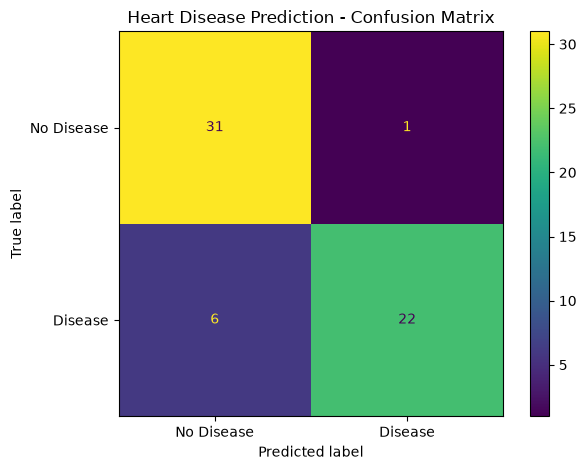

In [4]:
# 5. Inference and Evaluation
inference = VariableElimination(model)
predictions = []
probabilities_disease = []

for _, row in X_test.iterrows():
    evidence = {feature: int(row[feature]) for feature in X.columns}
    result = inference.query(
        variables=["disease"],
        evidence=evidence,
        show_progress=False
    )
    state_names = list(result.state_names["disease"])
    probability_map = dict(zip(state_names, result.values))
    p0 = float(probability_map.get(0, 0.0))
    p1 = float(probability_map.get(1, 0.0))
    predictions.append(int(p1 >= p0))
    probabilities_disease.append(p1)

y_pred = np.array(predictions)
y_actual = y_test.to_numpy()
accuracy = accuracy_score(y_actual, y_pred)

print("=" * 45)
print("BAYESIAN NETWORK EVALUATION")
print("=" * 45)
print(f"Bayesian Network Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(
    classification_report(
        y_actual,
        y_pred,
        labels=[0, 1],
        target_names=["No Disease", "Disease"],
        zero_division=0
    )
)

# Plot Confusion Matrix
cm = confusion_matrix(y_actual, y_pred, labels=[0, 1])
print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disease", "Disease"]
).plot()
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

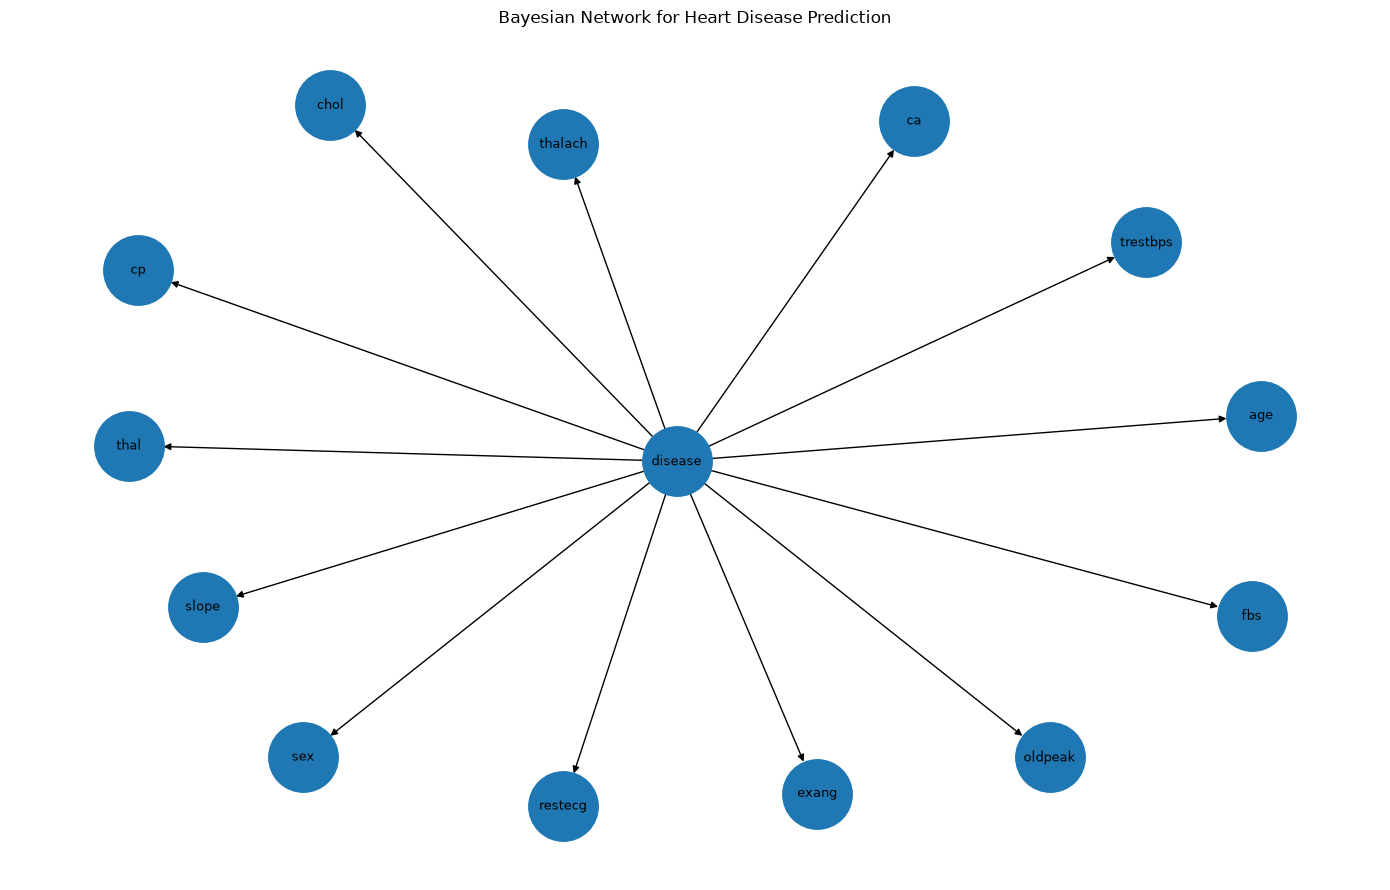

In [5]:
# 6. Visualize Bayesian Network
G = nx.DiGraph()
G.add_edges_from(model.edges())

plt.figure(figsize=(14, 9))
pos = nx.spring_layout(G, seed=42, k=1.5)
nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=2500,
    font_size=9,
    arrows=True
)
plt.title("Bayesian Network for Heart Disease Prediction")
plt.axis("off")
plt.tight_layout()
plt.show()

In [6]:
# 7. Test One Patient
patient = X_test.iloc[0]
evidence = {feature: int(patient[feature]) for feature in X.columns}

result = inference.query(
    variables=["disease"],
    evidence=evidence,
    show_progress=False
)
states = list(result.state_names["disease"])
probability_map = dict(zip(states, result.values))
p0 = float(probability_map.get(0, 0.0))
p1 = float(probability_map.get(1, 0.0))

print("=" * 45)
print("SAMPLE PATIENT PREDICTION")
print("=" * 45)
print("\nPatient attributes:")
print(patient)
print(f"\nP(No Disease | Evidence): {p0 * 100:.2f}%")
print(f"P(Disease    | Evidence): {p1 * 100:.2f}%")
print(
    "\nPredicted result:",
    "Heart Disease Present" if p1 >= p0 else "No Heart Disease"
)
actual = int(y_test.iloc[0])
print(
    "Actual result:",
    "Heart Disease Present" if actual == 1 else "No Heart Disease"
)
print("\nProgram completed successfully.")

SAMPLE PATIENT PREDICTION

Patient attributes:
age         0
sex         0
cp          3
trestbps    1
chol        0
fbs         0
restecg     0
thalach     2
exang       0
oldpeak     0
slope       0
ca          0
thal        0
Name: 295, dtype: int64

P(No Disease | Evidence): 99.63%
P(Disease    | Evidence): 0.37%

Predicted result: No Heart Disease
Actual result: No Heart Disease

Program completed successfully.
